# Boucles FOR en Python : guide complet, des bases à l'avancé

Notebook de l'article [Boucles FOR en Python : guide complet, des bases à l'avancé](https://moncoachdata.com/blog/python-boucles-for/) (MonCoachData). Exécute les cellules dans l'ordre.

Quand tu travailles avec des données, les boucles `for` sont un outil puissant, mais elles peuvent dérouter quand on débute. Voici donc un tutoriel complet sur les **boucles for Python**.

Tu vas voir comment elles servent à faire toutes sortes de choses utiles, notamment pour nettoyer et analyser des données en Python.

Ce guide réunit, au même endroit, les bases des boucles `for` et les techniques avancées : boucles sur les tuples, les dictionnaires, les tableaux NumPy et les DataFrames pandas, boucles imbriquées et graphiques avec Matplotlib. Tu peux le lire d'un bout à l'autre ou aller directement à la section qui t'intéresse.

**En bref :** une boucle `for` Python parcourt un objet itérable (liste, tuple, chaîne, dictionnaire…) et exécute la même action pour chaque élément. Pour les dictionnaires, on utilise `.items()` ; pour les tableaux NumPy à deux dimensions, `np.nditer()` ; pour les DataFrames pandas, `iterrows()` (lent : pandas sait faire sans boucle, de façon vectorisée). `break` arrête la boucle, `continue` saute seulement l'itération en cours.

## Qu'est-ce qu'une boucle for ?

Une boucle `for` parcourt un objet itérable et exécute la même action pour chacun de ses éléments. Dans la plupart des projets de Data Science, une boucle sert à parcourir un objet itérable (une liste, un tuple, un ensemble…) et à effectuer la même action pour chaque élément.

Un objet itérable est un objet qu'on peut parcourir avec une boucle, en obtenant un seul élément à la fois. Les listes sont itérables : elles renvoient leurs éléments dans l'ordre. Les chaînes de caractères aussi : elles renvoient un caractère à la fois.

Pour créer une boucle `for`, tu définis l'objet itérable à parcourir, puis l'action à effectuer sur chaque élément.

Voici la syntaxe générale :

```python
for object in collection_of_objects:
    # code à exécuter sur chaque objet
```

À chaque passage dans la boucle, la variable `object` prend la valeur de l'élément suivant de `collection_of_objects`, et Python exécute le code indenté pour cet élément.

Prenons un exemple rapide : une liste de prénoms, et une boucle qui affiche chaque prénom, dans l'ordre.

In [ ]:
our_list = ['Thomas', 'Pierre', 'Fatima', 'Alex']

for name in our_list:
    print(name)

Thomas
Pierre
Fatima
Alex


Une question se pose : d'où vient la variable `name` ? On ne l'a définie nulle part avant.

En fait, la boucle la crée toute seule. Tu peux lui donner n'importe quel nom ; on essaie simplement de choisir un nom cohérent (ici, `name` pour des prénoms).

Python considère ce nom comme la référence à chaque élément de la liste, au fur et à mesure de la boucle :

- `name` pointe vers « Thomas » à la première itération ;
- puis vers « Pierre » à la deuxième ;
- et ainsi de suite.

Le résultat est identique quel que soit le nom choisi. Si on remplace `name` par `x`, on obtient exactement le même affichage :

In [ ]:
for x in our_list:
    print(x)

Thomas
Pierre
Fatima
Alex


Cette technique fonctionne avec n'importe quel objet itérable. Les chaînes de caractères (*strings*) en sont : on peut donc parcourir chaque caractère d'une chaîne.

In [ ]:
for letter in 'Lily':
    print(letter)

L
i
l
y


## Comment utiliser une boucle for avec une liste de listes ?

En analyse de données, tu travailleras rarement avec des listes courtes et simples comme celle ci-dessus. En général, les jeux de données sont des tableaux, avec plusieurs lignes et colonnes.

En Python, on peut stocker ce type de données sous forme de liste de listes : chaque ligne du tableau est une liste, placée dans la liste principale. Les boucles permettent aussi de les parcourir.

Prenons un scénario plus réaliste : un petit tableau avec les prix et l'autonomie de plusieurs voitures électriques.

Voici ce même jeu de données sous forme de liste de listes :

In [ ]:
ev_data = [['vehicle', 'range', 'price'],
           ['Tesla Model 3 LR', '310', '49900'],
           ['Hyundai Ioniq EV', '124', '30315'],
           ['Chevy Bolt', '238', '36620']]

Remarque : l'autonomie (`range`) et le prix (`price`) sont stockés sous forme de chaînes de caractères plutôt que d'entiers. C'est fréquent, mais pour faire des calculs il faut les convertir en entiers.

Utilisons une boucle `for` pour parcourir la liste de listes, sélectionner l'autonomie de chaque voiture et la convertir en entier. Cela demande quelques manipulations.

**D'abord**, il faut ignorer la première ligne, qui contient les noms de colonnes : convertir une chaîne non numérique comme `'range'` en entier provoquerait une erreur. On utilise le *slicing* avec `ev_data[1:]` pour sélectionner toutes les lignes après la première.

**Ensuite**, à chaque itération, on sélectionne l'élément de la colonne `range`, la deuxième colonne du tableau. En Python, le premier élément d'un itérable a l'index 0, le deuxième l'index 1, etc. On utilise donc l'index 1 et on stocke la valeur dans la variable `ev_range`.

**Enfin**, on convertit l'autonomie en entier avec la fonction `int()` et on remplace la chaîne d'origine par cet entier.

In [ ]:
for row in ev_data[1:]:
    ev_range = row[1]
    ev_range = int(ev_range)
    row[1] = ev_range

print(ev_data)

[['vehicle', 'range', 'price'], ['Tesla Model 3 LR', 310, '49900'], ['Hyundai Ioniq EV', 124, '30315'], ['Chevy Bolt', 238, '36620']]


Maintenant que ces valeurs sont des entiers, on peut utiliser une boucle pour faire des calculs. Par exemple, calculons l'autonomie moyenne d'une voiture électrique de la liste : il faut additionner les autonomies, puis diviser par le nombre de voitures.

On crée d'abord une variable `total_range` pour stocker la somme. Puis on écrit une boucle qui ignore à nouveau la ligne d'en-tête et sélectionne la deuxième colonne (index 1). On ajoute chaque valeur à `total_range`, puis, une fois la boucle terminée, on divise par le nombre de voitures.

Ici, on obtient le nombre de voitures avec la longueur de la liste, ligne d'en-tête exclue. Avec une liste aussi courte, on pourrait simplement diviser par 3. Mais ce calcul serait faux dès qu'on ajouterait des véhicules : mieux vaut utiliser `len()`. Il suffira alors de ré-exécuter le code pour obtenir toujours la bonne réponse.

In [ ]:
total_range = 0

for row in ev_data[1:]:
    ev_range = row[1]
    total_range += ev_range

number_of_cars = len(ev_data[1:])

print(total_range / number_of_cars)

224.0


Une boucle peut contenir des instructions plus complexes. Répétons ces étapes pour la colonne `price`, cette fois dans une seule boucle : on convertit le prix en entier et on l'ajoute au total.

In [ ]:
total_price = 0

for row in ev_data[1:]:
    price = row[2]
    price = int(price)
    row[2] = price
    total_price += price

number_of_cars = len(ev_data[1:])

print(total_price / number_of_cars)

38945.0


On peut aussi imbriquer d'autres éléments dans une boucle : des instructions `if` / `else`, et même d'autres boucles `for`.

Par exemple, cherchons toutes les voitures qui ont plus de 200 miles d'autonomie. On crée d'abord une liste vide pour les accueillir. Puis on parcourt `ev_data` et on ajoute la ligne d'une voiture seulement si son autonomie dépasse 200 :

In [ ]:
long_range_car_list = []

for row in ev_data[1:]:
    ev_range = row[1]
    # condition : autonomie supérieure à 200 miles
    if ev_range > 200:
        long_range_car_list.append(row)

print(long_range_car_list)

[['Tesla Model 3 LR', 310, 49900], ['Chevy Bolt', 238, 36620]]


## Comment utiliser range, break et continue ?

Les techniques ci-dessus te mènent déjà loin. Voyons d'autres éléments, que tu utiliseras un peu moins souvent en Data Science, mais qui peuvent t'être utiles.

### Comment utiliser la fonction range() dans une boucle for ?

On peut utiliser une boucle `for` avec la fonction `range()` pour parcourir chaque nombre d'une plage donnée. Par exemple :

In [ ]:
for x in range(5, 9):
    print(x)

5
6
7
8


Python n'inclut pas la valeur maximale de `range` : c'est pourquoi le 9 n'apparaît pas. Pour compter de 5 à 9 inclus, il faut remplacer `range(5, 9)` par `range(5, 10)` :

In [ ]:
for x in range(5, 10):
    print(x)

5
6
7
8
9


Si tu ne donnes qu'un seul nombre à `range()`, Python le considère comme la valeur maximale, et utilise 0 comme valeur minimale par défaut :

In [ ]:
for x in range(3):
    print(x)

0
1
2


Tu peux aussi ajouter un troisième paramètre pour définir le pas, c'est-à-dire de combien chaque valeur augmente. Par défaut, il vaut 1. Avec un pas de 3, par exemple, on compte de trois en trois :

In [ ]:
for x in range(0, 9, 3):
    print(x)

0
3
6


### Comment parcourir une séquence par son index ?

On peut aussi utiliser l'index des éléments d'une séquence pour itérer. Le principe : calculer d'abord la longueur de la liste, puis parcourir la plage de cette longueur. Exemple :

In [ ]:
languages = ['Espagnol', 'Anglais', 'Français', 'Allemand', 'Irlandais', 'Chinois']

for index in range(len(languages)):
    print('Langue :', languages[index])

Langue : Espagnol
Langue : Anglais
Langue : Français
Langue : Allemand
Langue : Irlandais
Langue : Chinois


Ici, la boucle parcourt les index de la séquence de nombres créée par `range()`. On utilise aussi `len()`, car on a besoin du nombre d'éléments de la liste.

À chaque itération, on exécute le `print`. Pour chaque index de `range(len(languages))`, on affiche une langue. Comme la longueur de la liste est 6 (la valeur de `len(languages)`), on peut réécrire la boucle ainsi :

In [ ]:
for index in range(6):
    print('Langue :', languages[index])

Langue : Espagnol
Langue : Anglais
Langue : Français
Langue : Allemand
Langue : Irlandais
Langue : Chinois


**Bon à savoir :** quand tu as besoin à la fois de l'index et de l'élément, la fonction `enumerate()` est plus lisible et plus pythonique que `range(len(...))` :

In [ ]:
for index, language in enumerate(languages):
    print('Langue :', language, '(index', index, ')')

Langue : Espagnol (index 0 )
Langue : Anglais (index 1 )
Langue : Français (index 2 )
Langue : Allemand (index 3 )
Langue : Irlandais (index 4 )
Langue : Chinois (index 5 )


### À quoi sert l'instruction break ?

Par défaut, une boucle `for` parcourt chaque élément de l'objet itérable. C'est en général ce qu'on veut : appliquer la même action à tous les éléments.

Parfois, on veut arrêter la boucle quand une condition est remplie. L'instruction `break` sert à cela : utilisée avec un `if` dans une boucle `for`, elle permet de sortir de la boucle avant la fin.

Voici d'abord un exemple rapide, avec la liste de prénoms `our_list` créée plus haut :

In [ ]:
for name in our_list:
    break
    print(name)

Rien ne s'affiche. En effet, l'instruction `break` se trouve avant `print(name)` : dès que Python la voit, il arrête la boucle et n'exécute pas le code qui suit.

Ajoutons un `if` pour sortir de la boucle quand Python rencontre le prénom Alex :

In [ ]:
for name in our_list:
    if name == 'Alex':
        break
    print(name)

Thomas
Pierre
Fatima


Le prénom « Alex » n'est pas affiché. Voici ce qui se passe à chaque itération :

1. Python vérifie si le prénom est « Alex ». Ce n'est pas le cas : il exécute le reste de la boucle et affiche le prénom.
2. Même vérification pour le deuxième prénom : ce n'est pas « Alex », il l'affiche.
3. Idem pour le troisième.
4. Pour le quatrième, c'est bien « Alex » : `break` est exécuté et la boucle se termine.

Revenons au code sur les voitures à longue autonomie, pour un autre exemple. On insère une instruction `break` qui arrête la boucle dès que la chaîne `'Tesla'` apparaît :

In [ ]:
long_range_car_list = []

for row in ev_data[1:]:
    ev_range = row[1]
    if ev_range > 200:
        long_range_car_list.append(row)
    # si on rencontre 'Tesla', on arrête la boucle
    if 'Tesla' in row[0]:
        break

print(long_range_car_list)

[['Tesla Model 3 LR', 310, 49900]]


La Tesla est bien ajoutée à `long_range_car_list`, car l'ajout se fait avant le `if` qui contient le `break`.

La Chevy Bolt, en revanche, n'est pas ajoutée : bien que son autonomie dépasse 200 miles, `break` a arrêté la boucle avant que Python n'atteigne sa ligne.

N'oublie pas que les boucles s'exécutent dans l'ordre. Si la Bolt avait été placée avant la Tesla dans le jeu de données, elle aurait été incluse dans `long_range_car_list`.

### À quoi sert l'instruction continue ?

En parcourant un objet itérable comme une liste, on veut parfois ignorer une ou plusieurs lignes. Pour un cas simple comme sauter l'en-tête, le slicing suffit. Mais pour des conditions plus complexes, il devient vite impraticable.

On utilise alors l'instruction `continue` : elle ignore une seule itération et passe à la suivante. Quand Python rencontre `continue`, il s'arrête à ce point, passe à l'élément suivant et n'exécute pas le code situé en dessous.

Reprenons notre liste de prénoms et utilisons `continue` avec un `if` pour ignorer le prénom « Pierre » :

In [ ]:
for name in our_list:
    if name == 'Pierre':
        continue
    print(name)

Thomas
Fatima
Alex


Le prénom « Pierre » a été ignoré, les autres sont affichés dans l'ordre. Voici la différence entre `break` et `continue` :

- `break` met fin à la boucle entièrement ;
- `continue` termine seulement l'itération en cours et passe à l'élément suivant : la boucle continue.

Pour t'entraîner, dressons la liste des véhicules à courte autonomie avec `continue`. Au lieu de chercher les véhicules sous les 200 miles, on ajoute chaque véhicule à la liste, sauf si son autonomie dépasse 200 miles, auquel cas `continue` saute l'ajout :

In [ ]:
short_range_car_list = []

for row in ev_data[1:]:
    ev_range = row[1]
    # si l'autonomie dépasse 200, on passe à l'élément suivant
    if ev_range > 200:
        continue
    short_range_car_list.append(row)

print(short_range_car_list)

[['Hyundai Ioniq EV', 124, 30315]]


Ce n'est sans doute pas le moyen le plus efficace (ni le plus lisible) de construire cette liste, mais il montre bien le fonctionnement de `continue`. Détaillons ce qui se passe :

- **Premier passage** : Python regarde la ligne Tesla, dont l'autonomie dépasse 200 miles. Il exécute le `continue` du `if` et passe immédiatement à la ligne suivante.
- **Deuxième passage** : Python regarde la ligne Hyundai, dont l'autonomie est inférieure à 200 miles. La condition n'est pas remplie, donc il exécute la suite de la boucle et ajoute la ligne Hyundai à `short_range_car_list`.
- **Troisième passage** : Python regarde la ligne Chevy, dont l'autonomie dépasse 200 miles. Il exécute à nouveau `continue`. Comme il n'y a plus de ligne, la boucle se termine.

Plutôt simple, non ?

## Comment utiliser une boucle for avec d'autres structures de données ?

Dans le monde réel, tu ne travailleras pas qu'avec des listes. Voyons comment utiliser les boucles `for` avec des tuples, des dictionnaires, des tableaux NumPy et des DataFrames pandas.

### Comment parcourir un tuple ?

Les tuples (ou n-uplets) sont des séquences, comme les listes. Mais ils sont **immuables** : on ne peut pas les modifier ([en savoir plus sur les objets mutables et immuables en Python](https://moncoachdata.com/blog/donnees-mutables-et-immuables-python/)). Ils s'écrivent aussi avec des parenthèses plutôt que des crochets.

Malgré ces différences, parcourir un tuple ressemble beaucoup à parcourir une liste.

In [ ]:
x = (10, 20, 30, 40, 50)
for var in x:
    print("index " + str(x.index(var)) + " :", var)

index 0 : 10
index 1 : 20
index 2 : 30
index 3 : 40
index 4 : 50


Avec une liste de tuples, on peut accéder à chaque élément d'un tuple en mettant plusieurs variables dans la boucle `for` :

In [ ]:
x = [(1, 2), (3, 4), (5, 6)]
for a, b in x:
    print(a, "+", b, "=", a + b)

1 + 2 = 3
3 + 4 = 7
5 + 6 = 11


### Comment parcourir un dictionnaire ?

Les dictionnaires sont un autre type de données courant en Python. Les boucles `for` savent aussi les parcourir.

Un dictionnaire est composé de paires clé-valeur (*key-value*) : à chaque itération, il faut donc accéder à deux éléments. On appelle pour cela la méthode `.items()`, qui renvoie la clé et la valeur de chaque paire.

Imaginons un dictionnaire `stocks` qui contient des actions et leurs cours. Les valeurs sont données à titre d'exemple.

In [ ]:
stocks = {
    'AAPL': 187.31,
    'MSFT': 124.06,
    'META': 183.50
}

for key, value in stocks.items():
    print(key + " : " + str(value))

AAPL : 187.31
MSFT : 124.06
META : 183.5


Les noms `key` et `value` sont arbitraires : tu peux utiliser `k` et `v`, ou encore `x` et `y`.

### Comment parcourir un tableau NumPy ?

Voyons maintenant les boucles `for` avec des bibliothèques courantes de Data Science et leurs types de données.

Commençons par les tableaux NumPy. On crée d'abord des tableaux de nombres aléatoires :

In [ ]:
import numpy as np

np.random.seed(0)  # graine aléatoire pour reproduire le même résultat
x = np.random.randint(10, size=6)
y = np.random.randint(10, size=6)

Parcourir un tableau NumPy à une dimension ressemble beaucoup à parcourir une liste :

In [ ]:
for val in x:
    print(val)

5
0
3
3
7
9


Et pour un tableau à deux dimensions ? Avec la même syntaxe, chaque itération renvoie un tableau entier :

In [ ]:
# création d'un tableau à 2 dimensions
z = np.array([x, y])

for val in z:
    print(val)

[5 0 3 3 7 9]
[3 5 2 4 7 6]


Un tableau à deux dimensions est une paire de tableaux à une dimension. Pour visiter chaque élément plutôt que chaque tableau, on utilise la fonction NumPy `nditer()`, un itérateur multidimensionnel qui prend un tableau en argument.

Dans le code ci-dessous, la boucle parcourt chaque élément de `z` (notre tableau à deux dimensions) :

In [ ]:
for val in np.nditer(z):
    print(val)

5
0
3
3
7
9
3
5
2
4
7
6


On voit que la boucle énumère d'abord tous les éléments de `x`, puis tous ceux de `y`.

À retenir : pour les dictionnaires, il faut une **méthode** (`.items()`), alors que pour les tableaux NumPy, il faut une **fonction** (`np.nditer()`).

### Comment parcourir un DataFrame pandas ?

En Data Science, on travaille souvent avec des DataFrames pandas, que l'on peut aussi parcourir avec des boucles `for`.

Utilisons un petit fichier CSV qui contient le PIB, la capitale et la population de six pays (la cellule suivante le crée dans l'environnement). On le lit ensuite dans un DataFrame pandas.

Pandas fonctionne différemment de NumPy : si on parcourt un DataFrame comme un tableau NumPy, on obtient seulement les noms des colonnes :

In [ ]:
# Création du fichier gdp.csv : PIB (en billions de dollars), capitale et population de six pays
gdp_csv = """Country,Capital,GDP ($US Trillion),Population
Ireland,Dublin,0.3337,4784000
United Kingdom,London,2.622,66040000
United States,"Washington, D.C.",19.39,327200000
China,Beijing,12.24,1386000000
India,New Delhi,2.597,1339000000
Germany,Berlin,3.677,82790000
"""

with open("gdp.csv", "w") as f:
    f.write(gdp_csv)

In [ ]:
import pandas as pd

df = pd.read_csv('gdp.csv', index_col=0)
# supprime les espaces parasites dans les noms de colonnes
df.columns = df.columns.str.strip()

for val in df:
    print(val)

Capital
GDP ($US Trillion)
Population


Pour parcourir les lignes, il faut le demander explicitement avec la méthode `iterrows()`. Elle renvoie, pour chaque ligne, l'étiquette (le nom du pays) et la ligne entière sous forme de Series pandas :

In [ ]:
for label, row in df.iterrows():
    print(label)
    print(row)

Ireland
Capital                Dublin
GDP ($US Trillion)     0.3337
Population            4784000
Name: Ireland, dtype: object
United Kingdom
Capital                 London
GDP ($US Trillion)       2.622
Population            66040000
Name: United Kingdom, dtype: object
United States
Capital               Washington, D.C.
GDP ($US Trillion)               19.39
Population                   327200000
Name: United States, dtype: object
China
Capital                  Beijing
GDP ($US Trillion)         12.24
Population            1386000000
Name: China, dtype: object
India
Capital                New Delhi
GDP ($US Trillion)         2.597
Population            1339000000
Name: India, dtype: object
Germany
Capital                 Berlin
GDP ($US Trillion)       3.677
Population            82790000
Name: Germany, dtype: object


On peut aussi accéder à une valeur précise de la Series. Pour n'afficher que la capitale de chaque pays, on cible la colonne « Capital » :

In [ ]:
for label, row in df.iterrows():
    print(label + " : " + row["Capital"])

Ireland : Dublin
United Kingdom : London
United States : Washington, D.C.
China : Beijing
India : New Delhi
Germany : Berlin


Allons plus loin qu'un simple affichage : ajoutons une colonne de PIB par habitant avec une boucle. Rappelle-toi que la méthode `.loc[]` repère une ligne par son étiquette (ici, le pays).

Pour chaque pays, on divise le PIB total par la population, puis on multiplie par un billion (les PIB sont exprimés en billions de dollars) pour obtenir le PIB par habitant en dollars.

In [ ]:
for label, row in df.iterrows():
    df.loc[label, 'gdp_per_cap'] = row['GDP ($US Trillion)'] / row['Population'] * 1000000000000

print(df)

                         Capital  GDP ($US Trillion)  Population   gdp_per_cap
Country                                                                       
Ireland                   Dublin              0.3337     4784000  69753.344482
United Kingdom            London              2.6220    66040000  39703.210176
United States   Washington, D.C.             19.3900   327200000  59260.391198
China                    Beijing             12.2400  1386000000   8831.168831
India                  New Delhi              2.5970  1339000000   1939.507095
Germany                   Berlin              3.6770    82790000  44413.576519


**Bon à savoir :** `iterrows()` est pratique pour comprendre le principe, mais lent sur de gros DataFrames. Pour créer une colonne calculée, pandas sait faire la même chose sans boucle, de façon vectorisée et bien plus rapide :

In [ ]:
df['gdp_per_cap'] = df['GDP ($US Trillion)'] / df['Population'] * 1000000000000

## Qu'est-ce qu'une boucle imbriquée ?

Python permet d'utiliser une boucle dans une autre boucle : une boucle externe contient une boucle interne.

Voici la structure :

```python
for iterator_var in sequence:
    for iterator_var in sequence:
        # ...
```

Les boucles imbriquées sont utiles pour parcourir une liste de listes. Avec une seule boucle `for`, chaque liste interne est traitée comme un seul élément :

In [ ]:
languages = [['Espagnol', 'Anglais', 'Français', 'Allemand'], ['Python', 'Java', 'Javascript', 'C++']]

for lang in languages:
    print(lang)

['Espagnol', 'Anglais', 'Français', 'Allemand']
['Python', 'Java', 'Javascript', 'C++']


Pour accéder à chaque élément des listes internes, on utilise une boucle `for` imbriquée :

In [ ]:
for x in languages:
    print("------")
    for lang in x:
        print(lang)

------
Espagnol
Anglais
Français
Allemand
------
Python
Java
Javascript
C++


La boucle externe parcourt la liste principale (deux sous-listes ici), et la boucle interne parcourt chaque sous-liste. La boucle externe fait donc 2 itérations et, à chacune, la boucle interne affiche tous les éléments de la sous-liste correspondante.

Autrement dit, Python entre dans la boucle externe, exécute entièrement la boucle interne, puis revient à la boucle externe, jusqu'à avoir parcouru tous ses éléments.

### Comment utiliser continue dans une boucle imbriquée ?

Pour exclure une langue précise dans la boucle interne, on utilise l'instruction `continue` : elle saute une partie de la boucle quand une condition est remplie.

In [ ]:
for x in languages:
    print("------")
    for lang in x:
        if lang == "Allemand":
            continue
        print(lang)

------
Espagnol
Anglais
Français
------
Python
Java
Javascript
C++


Dans la boucle interne, si `lang` vaut « Allemand », Python ignore cette itération uniquement et continue avec le reste. La boucle n'est pas interrompue.

## Comment tracer des graphiques avec des boucles for ?

Les boucles servent aussi à générer des graphiques : on utilise chaque élément d'une collection pour tracer un sous-graphique ou un nouveau graphique. Prenons le célèbre jeu de données *iris* (chargé ici depuis une copie publique sur GitHub) pour faire des tracés avec des boucles.

Commençons par un nuage de points de la longueur et de la largeur des sépales :

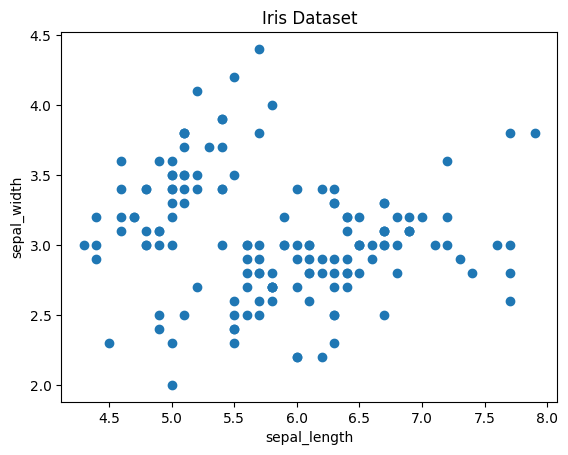

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Jeu de données Iris (copie hébergée sur le GitHub de MonCoachData)
URL = "https://raw.githubusercontent.com/moncoachdata/blog-data-science/main/python-boucles-for/iris.csv"

df = pd.read_csv(URL)

# créer une figure et un axe
fig, ax = plt.subplots()

# nuage de points : sepal_length et sepal_width
ax.scatter(df['sepal_length'], df['sepal_width'])

# titre et intitulés des axes
ax.set_title('Iris Dataset')
ax.set_xlabel('sepal_length')
ax.set_ylabel('sepal_width')

plt.show()

On peut donner plus de sens au graphique en colorant chaque point selon l'espèce de la fleur. Pour cela, on trace chaque point séparément avec une boucle `for`, en lui passant la couleur correspondante :

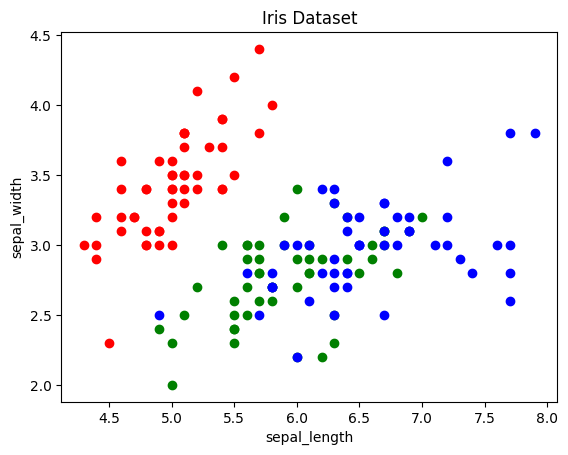

In [ ]:
# dictionnaire des couleurs
colors = {'setosa': 'r', 'versicolor': 'g', 'virginica': 'b'}

# créer une figure et un axe
fig, ax = plt.subplots()

# tracer chaque point
for i in range(len(df['sepal_length'])):
    ax.scatter(df['sepal_length'][i], df['sepal_width'][i], color=colors[df['species'][i]])

# titre et intitulés des axes
ax.set_title('Iris Dataset')
ax.set_xlabel('sepal_length')
ax.set_ylabel('sepal_width')

plt.show()

Et pour visualiser la distribution de chaque caractéristique du jeu de données ? On crée une grille de sous-graphiques avec `plt.subplots()` (2 lignes, 2 colonnes) et une boucle qui trace un histogramme dans chaque case :

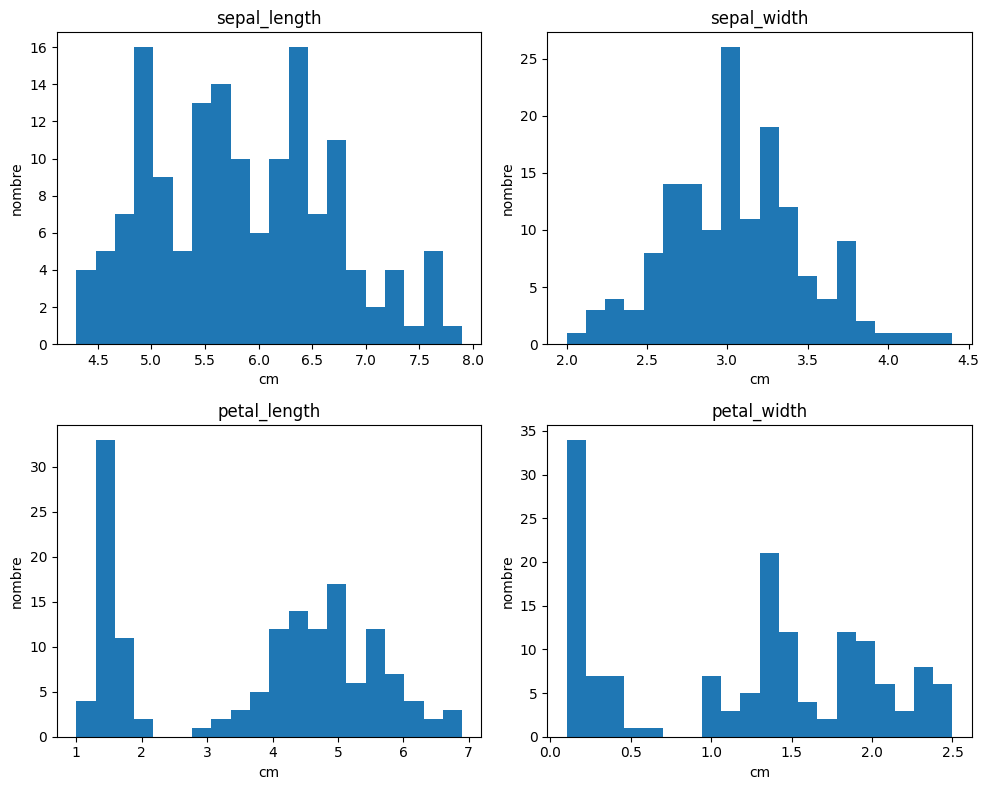

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, column in zip(axes.flatten(), df.columns[:4]):
    ax.hist(df[column], bins=20)
    ax.set(title=column, xlabel='cm', ylabel='nombre')

fig.tight_layout()
plt.show()

Sans entrer dans le détail de la syntaxe Matplotlib, voici les composants principaux de ce graphique :

- `plt.subplots(2, 2)` - crée la grille de 2 x 2 sous-graphiques et en définit la taille globale ;
- `zip()` - fonction native de Python qui parcourt plusieurs itérables de même longueur en même temps ;
- `axes.flatten()` - méthode des tableaux NumPy qui aplatit la grille en une seule liste de sous-graphiques ;
- `ax.set()` - définit en une seule fois les attributs d'un objet axes (titre, intitulés…).